# UniLex: Student Question Classification
This experiment compares TF-IDF + Logistic Regression with Sentence-BERT + Logistic Regression for mapping English questions to 16 UniLex concepts. Both methods are evaluated on the same held-out questions using Accuracy and Macro F1.

**Experimental question:** Which method classifies student queries to the correct concept more reliably?

## 1. Setup
**Platform:** Google Colab / Python 3.12. CPU execution.

The setup cell installs missing dependencies. An internet connection is required for the initial model download. Package versions are recorded below. The experiment uses a fixed random seed of 42.

In [1]:
import sys, subprocess, importlib.util
packages = {'sentence_transformers':'sentence-transformers', 'sklearn':'scikit-learn',
            'pandas':'pandas', 'matplotlib':'matplotlib', 'seaborn':'seaborn'}
# Install missing packages; export actual versions for reproducibility.
missing = [pkg for mod,pkg in packages.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
import os, random, re, json, hashlib, io
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from importlib.metadata import version
SEED = 42
random.seed(SEED); np.random.seed(SEED)
OUTPUT = Path('unilex_outputs'); OUTPUT.mkdir(exist_ok=True)
versions = {p: version(p) for p in packages.values()}
versions['python'] = sys.version.split()[0]
print(versions)
(OUTPUT/'environment.json').write_text(json.dumps(versions, indent=2))


{'sentence-transformers': '5.1.2', 'scikit-learn': '1.8.0', 'pandas': '2.2.3', 'matplotlib': '3.10.8', 'seaborn': '0.13.2', 'python': '3.12.14'}


## 2. Data
The dataset contains 320 questions across 16 concepts: 240 AI-assisted questions and 80 Stack Exchange questions. The two team-approved CSV files are concatenated without changing their field values, labels, reviewer names or approval statuses. Data are read from `UniLex_Questions.csv` in the working directory.

Case and whitespace are normalized for duplicate checks only. Empty questions, duplicate identifiers and conflicting labels are checked. TF-IDF lowercases text and removes English stop words within its vectorizer; SBERT receives the original question text.

The task is topic classification. Some Stack Exchange titles refer to multiple topics or require additional context. Their supplied labels are retained unchanged and this ambiguity is considered in the interpretation of results.

In [2]:
DATA_PATH = Path('UniLex_Questions.csv')
df = pd.read_csv(DATA_PATH).fillna('')

print('Input rows:', len(df))
print('Approval status counts:', df.review_status.value_counts().to_dict())
df = df[df.review_status.str.strip().str.lower().eq('approved')].copy()
def normalize(text):
    return ' '.join(str(text).casefold().split())
df['query_key'] = df['query'].map(normalize)
assert df.query_key.ne('').all(), 'Empty questions must be fixed.'
assert df.groupby('query_key').concept.nunique().max() == 1, 'Conflicting labels.'
assert not df.id.duplicated().any(), 'Duplicate IDs.'
df = df.drop_duplicates('query_key').reset_index(drop=True)
CONCEPTS = ['Overfitting','Underfitting','Regularization','Dropout','Cross-validation',
 'Gradient Descent','Learning Rate','Backpropagation','Tokenization','Stop Word',
 'Stemming','Lemmatization','TF-IDF','Hallucination','Transfer Learning','Confusion Matrix']
assert set(df.concept) == set(CONCEPTS)
print('Total approved unique questions:',len(df))
display(df.groupby('source').size().rename('rows').to_frame())
display(pd.crosstab(df.concept, df.source).reindex(CONCEPTS))


Input rows: 320
Approval status counts: {'approved': 320}
Total approved unique questions: 320
                rows
source              
AI-assisted      240
Stack Exchange    80
source             AI-assisted  Stack Exchange
concept                                       
Overfitting                 15               5
Underfitting                15               5
Regularization              15               5
Dropout                     15               5
Cross-validation            15               5
Gradient Descent            15               5
Learning Rate               15               5
Backpropagation             15               5
Tokenization                15               5
Stop Word                   15               5
Stemming                    15               5
Lemmatization               15               5
TF-IDF                      15               5
Hallucination               15               5
Transfer Learning           15               5
Confusion Matrix      

### Data Partitioning
For each concept, the three Stack Exchange questions with the highest numeric IDs form the test set. Three questions are sampled from the remaining pool for development using seed 42. The rest form the training pool.

Exact query and ID overlap are checked. A character n-gram similarity screen flags cross-split near-duplicates. Linked training rows are quarantined from model fitting, while the input CSV remains unchanged. Partition sizes and quarantined IDs are printed below. A development/test conflict stops execution rather than silently changing the fixed test set.

The test set contains only Stack Exchange questions. Both methods use identical partitions. Lexical screening does not detect every semantic paraphrase.

In [3]:
test_parts=[]; dev_parts=[]; train_parts=[]
for concept in CONCEPTS:
    part=df[df.concept.eq(concept)].copy()
    se=part[part.id.str.startswith('SE')].copy()
    se['id_number']=se.id.str.extract(r'(\d+)')[0].astype(int)
    assert len(se)>=3, f'Need at least 3 SE rows for {concept}'
    test=se.sort_values('id_number').tail(3).drop(columns='id_number')
    remaining=part[~part.id.isin(test.id)]
    assert len(remaining)>=4, f'Insufficient dev/train rows for {concept}'
    dev=remaining.sample(n=3,random_state=SEED)
    train=remaining[~remaining.id.isin(dev.id)]
    test_parts.append(test); dev_parts.append(dev); train_parts.append(train)
train=pd.concat(train_parts).reset_index(drop=True)
dev=pd.concat(dev_parts).reset_index(drop=True)
test=pd.concat(test_parts).reset_index(drop=True)
for a,b in [(train,dev),(train,test),(dev,test)]:
    assert not set(a.query_key)&set(b.query_key)
    assert not set(a.id)&set(b.id)
assert len(test)==48 and len(dev)==48
for name,part in [('train',train),('dev',dev),('test',test)]:
    print(name,len(part)); part.to_csv(OUTPUT/f'{name}.csv',index=False)
# Screening uses only question text, never test performance for model selection.
audit=pd.concat([train.assign(split='train'),dev.assign(split='dev'),test.assign(split='test')],ignore_index=True)
screen=TfidfVectorizer(analyzer='char_wb',ngram_range=(3,5)).fit_transform(audit['query'])
sim=(screen@screen.T).toarray()
pairs=[]
for i in range(len(audit)):
    for j in range(i+1,len(audit)):
        if sim[i,j]>=0.70 and audit.iloc[i]['split']!=audit.iloc[j]['split']:
            pairs.append({'id_a':audit.iloc[i].id,'id_b':audit.iloc[j].id,
                          'similarity':float(sim[i,j]),'query_a':audit.iloc[i]['query'],
                          'query_b':audit.iloc[j]['query']})
pair_table=pd.DataFrame(pairs,columns=['id_a','id_b','similarity','query_a','query_b'])
pair_table.to_csv(OUTPUT/'cross_split_similarity_review.csv',index=False)
display(pair_table)
# Keep the fixed held-out questions; quarantine linked training questions.
quarantine_ids=set()
for pair in pairs:
    a,b=pair['id_a'],pair['id_b']
    if a in set(train.id): quarantine_ids.add(a)
    elif b in set(train.id): quarantine_ids.add(b)
    else: raise ValueError('Similar dev/test questions found; revise grouped split before fitting.')
quarantine=train[train.id.isin(quarantine_ids)].copy()
train=train[~train.id.isin(quarantine_ids)].reset_index(drop=True)
quarantine.to_csv(OUTPUT/'quarantined_train_rows.csv',index=False)
train.to_csv(OUTPUT/'train.csv',index=False)
print('Quarantined near-duplicate training IDs:', sorted(quarantine_ids))
print('Final sizes:',len(train),len(dev),len(test))
print('Lexical screening does not establish complete semantic independence.')


train 224
dev 48
test 48
    id_a  ...                                            query_b
0  SE026  ...  Batch gradient descent versus stochastic gradi...

[1 rows x 5 columns]
Quarantined near-duplicate training IDs: ['SE026']
Final sizes: 223 48 48
Lexical screening does not establish complete semantic independence.


## 3. Method 1
**TF-IDF + Logistic Regression.** The TF-IDF vocabulary and inverse document frequencies are fitted on training questions only. Features include unigrams and bigrams, sublinear term frequency and English stop-word removal.

Logistic Regression is evaluated with C ∈ {0.1, 1, 10, 100}. The value with the highest development Macro F1 is selected; ties favor the smaller C. Test data are not used for parameter selection.

In [4]:
C_GRID=[0.1,1,10,100]
def select_classifier(X_train,X_dev):
    rows=[]; best=None; best_score=-1
    for c in C_GRID:
        model=LogisticRegression(C=c,max_iter=1000,random_state=SEED)
        model.fit(X_train,train.concept)
        score=f1_score(dev.concept,model.predict(X_dev),labels=CONCEPTS,average='macro',zero_division=0)
        rows.append({'C':c,'dev_macro_f1':score})
        if score>best_score:
            best_score=score; best=model
    display(pd.DataFrame(rows))
    return best
vectorizer=TfidfVectorizer(lowercase=True,ngram_range=(1,2),sublinear_tf=True,stop_words='english')
X_train=vectorizer.fit_transform(train['query'])
X_dev=vectorizer.transform(dev['query'])
tfidf_model=select_classifier(X_train,X_dev)
print('Selected C:',tfidf_model.C)


       C  dev_macro_f1
0    0.1      0.671131
1    1.0      0.785714
2   10.0      0.838839
3  100.0      0.823462
Selected C: 10


## 4. Method 2
**SBERT + Logistic Regression.** The pretrained `all-MiniLM-L6-v2` encoder produces normalized sentence embeddings. Encoder weights remain frozen. Logistic Regression uses the same training and development partitions and the same C grid as Method 1.

In [5]:
from sentence_transformers import SentenceTransformer
import torch
torch.manual_seed(SEED)
MODEL_NAME='sentence-transformers/all-MiniLM-L6-v2'
# Pin the public model revision to make future reruns reproducible.
MODEL_REVISION='c9745ed1d9f207416be6d2e6f8de32d1f16199bf'
encoder=SentenceTransformer(MODEL_NAME,revision=MODEL_REVISION,device='cpu')
def embeddings(queries):
    return encoder.encode(list(queries),normalize_embeddings=True,show_progress_bar=False)
E_train=embeddings(train['query']); E_dev=embeddings(dev['query'])
sbert_model=select_classifier(E_train,E_dev)
print('Selected C:',sbert_model.C)


       C  dev_macro_f1
0    0.1      0.812946
1    1.0      0.856994
2   10.0      0.835863
3  100.0      0.835863
Selected C: 1


## 5. Results
Both methods are evaluated on the same 48 held-out questions. The table reports Accuracy, Macro F1 and the selected C. Classification reports and confusion matrices describe performance for each concept.

TF-IDF + LR
                   precision    recall  f1-score   support

      Overfitting       0.67      0.67      0.67         3
     Underfitting       0.67      0.67      0.67         3
   Regularization       1.00      1.00      1.00         3
          Dropout       0.75      1.00      0.86         3
 Cross-validation       0.75      1.00      0.86         3
 Gradient Descent       1.00      1.00      1.00         3
    Learning Rate       1.00      1.00      1.00         3
  Backpropagation       1.00      0.67      0.80         3
     Tokenization       1.00      1.00      1.00         3
        Stop Word       1.00      1.00      1.00         3
         Stemming       1.00      1.00      1.00         3
    Lemmatization       1.00      0.67      0.80         3
           TF-IDF       1.00      1.00      1.00         3
    Hallucination       1.00      1.00      1.00         3
Transfer Learning       1.00      1.00      1.00         3
 Confusion Matrix       1.00      1.00     

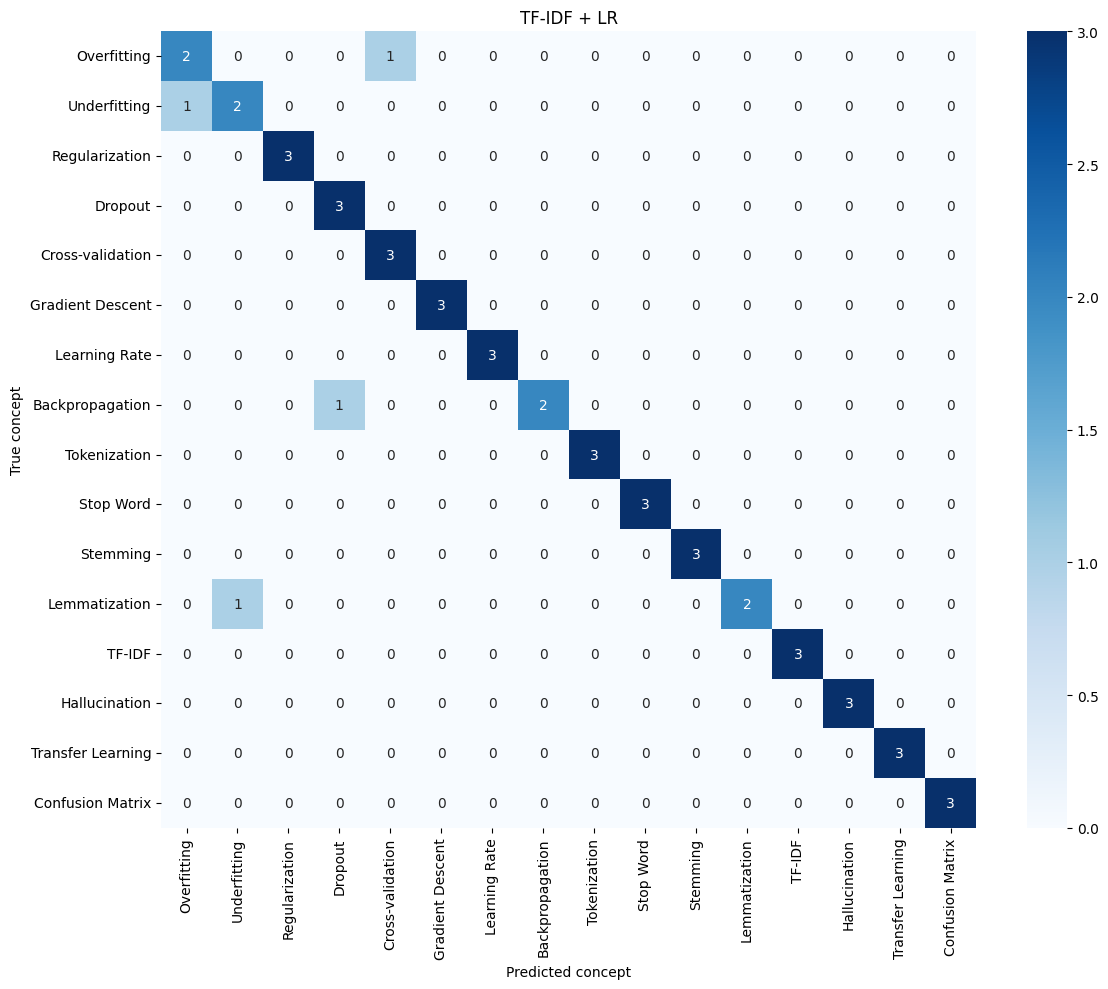

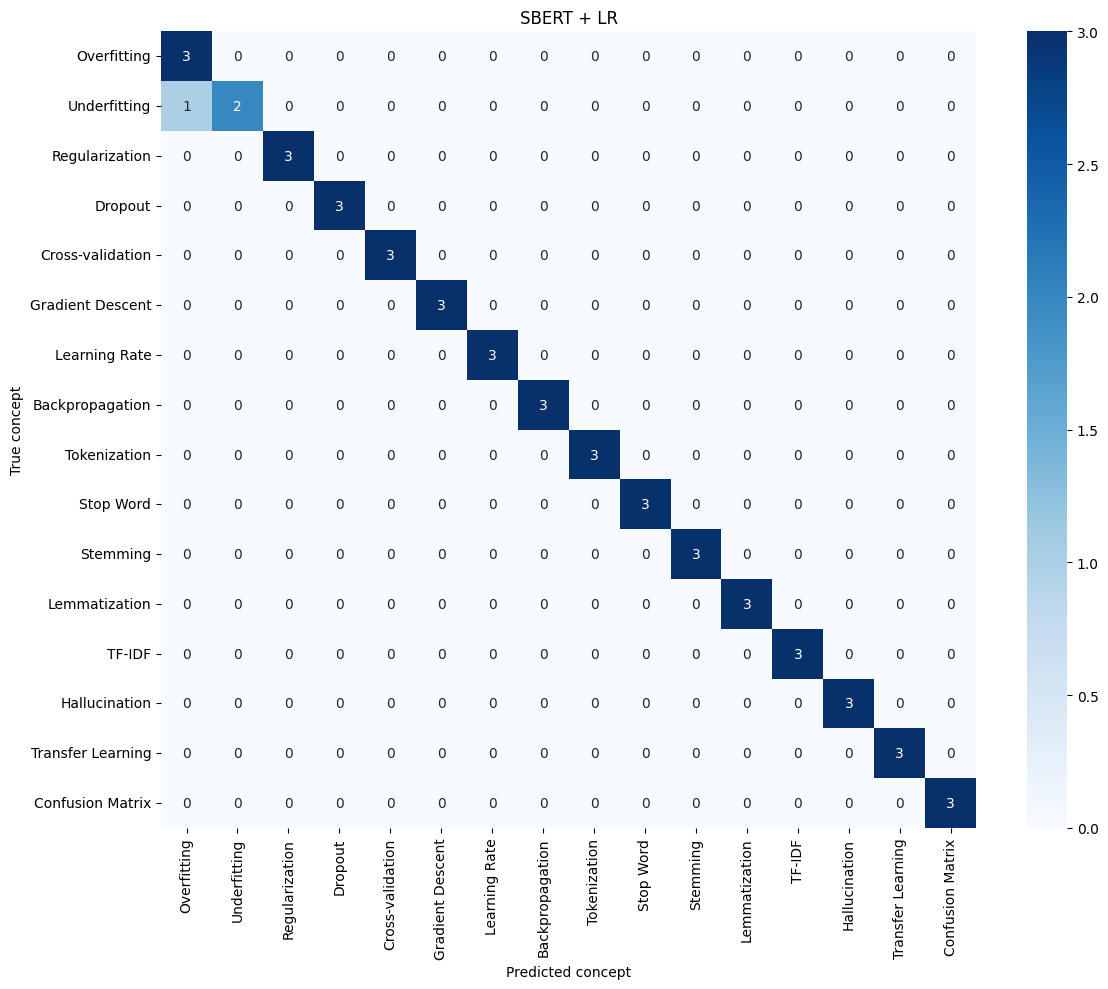

In [6]:
predictions={'TF-IDF + LR':tfidf_model.predict(vectorizer.transform(test['query'])),
             'SBERT + LR':sbert_model.predict(embeddings(test['query']))}
rows=[]
for name,model in [('TF-IDF + LR',tfidf_model),('SBERT + LR',sbert_model)]:
    pred=predictions[name]
    rows.append({'Method':name,'C':model.C,'Accuracy':accuracy_score(test.concept,pred),
                 'Macro F1':f1_score(test.concept,pred,labels=CONCEPTS,average='macro',zero_division=0)})
    print(name)
    print(classification_report(test.concept,pred,labels=CONCEPTS,zero_division=0))
    fig,ax=plt.subplots(figsize=(12,10))
    sns.heatmap(confusion_matrix(test.concept,pred,labels=CONCEPTS),annot=True,fmt='d',
                xticklabels=CONCEPTS,yticklabels=CONCEPTS,cmap='Blues',ax=ax)
    ax.set(xlabel='Predicted concept',ylabel='True concept',title=name)
    fig.tight_layout(); fig.savefig(OUTPUT/(name.replace(' ','_')+'_confusion.png'),dpi=150)
    plt.show()
results=pd.DataFrame(rows); display(results); results.to_csv(OUTPUT/'results.csv',index=False)
a,b=results.iloc[0],results.iloc[1]
diff=b['Macro F1']-a['Macro F1']
if abs(diff)<1e-12:
    print('The methods tied on test Macro F1.')
else:
    winner='SBERT + LR' if diff>0 else 'TF-IDF + LR'
    print(f'{winner} achieved higher test Macro F1 by {abs(diff):.4f}.')
print(f"SBERT minus TF-IDF Accuracy: {b['Accuracy']-a['Accuracy']:+.4f}.")
print('These results describe this 48-question, Stack Exchange-only test set; they do not establish performance on all student questions.')
test_predictions=test.copy()
for name,pred in predictions.items(): test_predictions[name]=pred
test_predictions.to_csv(OUTPUT/'test_predictions.csv',index=False)


### Error Analysis
The error analysis selects up to three misclassified questions and supplements them with difficult correct cases if fewer errors occur. The analysis compares both predictions with the dataset label and examines lexical coverage and question ambiguity. Proposed explanations describe plausible causes rather than proven model reasoning.

In [7]:
p=test_predictions.copy()
p['wrong_tfidf']=p['TF-IDF + LR'].ne(p.concept)
p['wrong_sbert']=p['SBERT + LR'].ne(p.concept)
p['disagreement']=p['TF-IDF + LR'].ne(p['SBERT + LR'])
p['confidence']=np.minimum(tfidf_model.predict_proba(vectorizer.transform(test['query'])).max(axis=1),
                            sbert_model.predict_proba(embeddings(test['query'])).max(axis=1))
errors=p[p.wrong_tfidf|p.wrong_sbert].copy()
errors.to_csv(OUTPUT/'all_errors.csv',index=False)
selected=errors.sort_values(['disagreement','confidence'],ascending=[False,True]).head(3)
if len(selected)<3:
    correct=p[~p.wrong_tfidf & ~p.wrong_sbert].sort_values('confidence').head(3-len(selected))
    selected=pd.concat([selected,correct])
for _,r in selected.iterrows():
    print('Question:',r['query'])
    print('True:',r.concept,'| TF-IDF:',r['TF-IDF + LR'],'| SBERT:',r['SBERT + LR'])
    if not (r.wrong_tfidf or r.wrong_sbert):
        print('Difficult correct example: among the lowest classifier confidence values for jointly correct questions. Confidence is not calibrated.')
    elif r.id == 'SE005':
        print('The title only says validation loss rises; it does not say training loss falls. Overfitting is plausible but not uniquely established. Learning-rate instability and other causes are possible. This is an ambiguous gold-label example, not proof that both models misunderstand overfitting.')
    elif r.id == 'SE040':
        known=[t for t in vectorizer.build_analyzer()(r['query']) if t in vectorizer.vocabulary_]
        print('Observed TF-IDF vocabulary matches:', known)
        print('The spaced phrase back propagation and abbreviation CNN can limit lexical coverage. Different predictions may reflect representation and training differences; this is a hypothesis, not proof of model reasoning.')
    elif r.id in ['SE055', 'SE059', 'SE075']:
        print('This title involves overlapping concepts or an unspecified task. The supplied label is retained, but disagreement may reflect ambiguity in the question rather than a clear model failure.')
    elif r.disagreement:
        print('Hypothesis: lexical cues and semantic embeddings emphasize different features; explicit concept names and indirect descriptions provide different cues.')
    else:
        print('Hypothesis: shared terminology or limited training examples may confuse the target with',r['TF-IDF + LR']+'. The title may lack sufficient context to identify a unique concept.')
    print('Source:',r.source_url,'\n')
if not p.disagreement.any(): print('No method-disagreement examples exist in this test set.')


Question: What does it mean when validation loss increases over several epochs?
True: Overfitting | TF-IDF: Cross-validation | SBERT: Overfitting
The title only says validation loss rises; it does not say training loss falls. Overfitting is plausible but not uniquely established. Learning-rate instability and other causes are possible. This is an ambiguous gold-label example, not proof that both models misunderstand overfitting.
Source: https://datascience.stackexchange.com/questions/134201/what-does-it-mean-when-validation-loss-increases-over-several-epochs 

Question: back propagation in CNN
True: Backpropagation | TF-IDF: Dropout | SBERT: Backpropagation
Observed TF-IDF vocabulary matches: ['cnn']
The spaced phrase back propagation and abbreviation CNN can limit lexical coverage. Different predictions may reflect representation and training differences; this is a hypothesis, not proof of model reasoning.
Source: https://datascience.stackexchange.com/questions/27506/back-propagation-

### Error Analysis: SBERT errors and the size of the difference
The cell above shows questions where the two methods disagree. This cell lists **every** question that SBERT got wrong and every question that TF-IDF got wrong, so both methods' errors are covered. It also states how large the difference between the methods is, because the test set has only 48 questions (one question is about 2 percentage points). Explanations are hypotheses about plausible causes, not proof of how either model reasons.

In [ ]:
n_tfidf=int(p.wrong_tfidf.sum()); n_sbert=int(p.wrong_sbert.sum())
print(f'TF-IDF + LR wrong on {n_tfidf} of {len(p)} test questions; SBERT + LR wrong on {n_sbert} of {len(p)}.')
print(f'Difference: {abs(n_tfidf-n_sbert)} question(s). With only 3 test questions per concept, this is a small sample, so the ranking is suggestive, not conclusive.\n')
for name,col in [('SBERT + LR','wrong_sbert'),('TF-IDF + LR','wrong_tfidf')]:
    rows=p[p[col]]
    print('='*70); print(name,'errors:',len(rows)); print('='*70)
    for _,r in rows.iterrows():
        other='SBERT + LR' if name=='TF-IDF + LR' else 'TF-IDF + LR'
        print('Question:',r['query'])
        print('True:',r.concept,'| predicted by',name+':',r[name],'| other method:',r[other])
        words=[t for t in vectorizer.build_analyzer()(r['query']) if t in vectorizer.vocabulary_]
        print('Known TF-IDF vocabulary in this question:',words if words else 'none')
        print('Concept named in the question:', 'yes' if r.concept.lower().replace('-',' ') in r['query'].lower().replace('-',' ') else 'no')
        print('Source:',r.source_url,'\n')
print('Hypotheses only: errors tend to occur when a title names no concept word, mentions another concept (for example CNN, validation loss, or two techniques together), or needs context that a short title does not give.')


### Member Examples
Eight original questions, two per member, are evaluated separately using the fitted models. These examples are excluded from training, development, test partitions and all reported test metrics.

In [8]:
MEMBER_PATH = Path('member_examples.csv')
if not MEMBER_PATH.exists():
    print('Member examples: dataset not yet provided.')
else:
    members = pd.read_csv(MEMBER_PATH).fillna('')
    required = {'member', 'date_added', 'query', 'concept'}
    assert required.issubset(members.columns), f'Required columns: {sorted(required)}'
    assert len(members) == 8, 'Eight member questions are required.'
    assert members[list(required)].apply(lambda col: col.astype(str).str.strip().ne('').all()).all()
    author_counts = members['member'].str.strip().str.casefold().value_counts()
    assert len(author_counts) == 4 and author_counts.eq(2).all(), 'Two questions per member are required.'
    assert set(members.concept).issubset(CONCEPTS), 'Unknown concept label.'
    member_keys = members['query'].map(normalize)
    assert not member_keys.duplicated().any(), 'Member questions must be distinct.'
    assert not set(member_keys) & set(df.query_key), 'Member questions must be separate from the main dataset.'
    # Inference only: member examples never affect fitting, tuning or test metrics.
    member_results = members[['member', 'date_added', 'query', 'concept']].copy()
    member_results['TF-IDF + LR'] = tfidf_model.predict(vectorizer.transform(members['query']))
    member_results['SBERT + LR'] = sbert_model.predict(embeddings(members['query']))
    display(member_results)
    member_results.to_csv(OUTPUT / 'member_predictions.csv', index=False)


Member examples: dataset not yet provided.


## 6. Try it
The `try_it(text)` function displays predictions from both fitted models without retraining. The three example calls include empty input.

In [9]:
def try_it(text):
    if not isinstance(text,str) or not text.strip():
        print('Please enter a student question first.'); return
    text=text.strip()
    print('Question:',text)
    print('TF-IDF + LR:',tfidf_model.predict(vectorizer.transform([text]))[0])
    print('SBERT + LR:',sbert_model.predict(embeddings([text]))[0])
try_it('My model does well on training examples but struggles with new data. Why?')
try_it('How can I turn words into their dictionary forms?')
try_it('   ')


Question: My model does well on training examples but struggles with new data. Why?
TF-IDF + LR: Overfitting
SBERT + LR: Overfitting
Question: How can I turn words into their dictionary forms?
TF-IDF + LR: Lemmatization
SBERT + LR: Lemmatization
Please enter a student question first.


## 7. Sources
### Sources
- Stack Exchange questions: individual links and supplied credit information are retained in the dataset columns `source_url` and `license_or_credit`.
- AI-assisted questions were drafted with Claude (Anthropic) and reviewed by the team. Forty-five questions were clarified or corrected with AI assistance before the team confirmed approval of the revised version.
- Reimers, N., & Gurevych, I. (2019). [Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks](https://aclanthology.org/D19-1410/).
- Sentence Transformers: [all-MiniLM-L6-v2](https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2).
- Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). [BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding](https://aclanthology.org/N19-1423/).
- UniLex question dataset: `UniLex_Questions.csv`, comprising the team-reviewed AI-assisted and Stack Exchange questions used in this experiment.
- scikit-learn: [Logistic Regression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).

### Limitations
The test set contains three questions per concept and is restricted to Stack Exchange titles. Some titles explicitly name the concept, while others require missing context or admit multiple interpretations. These properties can affect both measured accuracy and label reliability. Public question authors are not verified students. Exact deduplication and lexical screening do not establish complete semantic independence between partitions. Results therefore describe this specific dataset and split rather than general performance on student questions.

Dataset review occurred after an earlier exploratory evaluation. Recomputed scores on reused or revised partitions are exploratory; a new untouched evaluation set would be needed for a strictly independent final assessment.